# Construccion de arquetipos de ataques de phishing (Fase 5)

**Trabajo de graduacion:** prototipo de deteccion de phishing con un LLM orquestador
y varios servidores MCP.

**Objetivo de este notebook**

Construir los **arquetipos de ataque** que usara el servidor MCP de analisis de
patrones (`pattern-analysis-mcp`). Solo se agrupan los correos de phishing
(`label == 1`) del corpus Al-Subaiey completo (`data/corpus_construccion.csv`).
El objetivo no es separar phishing de legitimo por clustering (para eso esta el
clasificador principal), sino **caracterizar los patrones de ataque** que existen
dentro del phishing: que tacticas de ingenieria social y que emociones explotan
los distintos tipos de correo de phishing.

**Flujo del notebook**

1. Carga de `data/corpus_construccion.csv` y filtrado a solo `label == 1` (phishing).
2. Generacion de embeddings locales con `sentence-transformers` (con cache en disco).
3. Busqueda del numero optimo de clusters `k`: se explora un rango amplio (5 a 20)
   con KMeans, usando el metodo del codo (inertia) y el Silhouette Score
   calculado sobre el corpus completo (sin submuestreo). El `k` optimo es el que
   maximiza el Silhouette Score en el rango explorado.
4. Entrenamiento del modelo KMeans final con el `k` optimo.
5. Perfil de cada arquetipo: terminos/frases mas frecuentes (TF-IDF), 3 correos
   representativos (mas cercanos al centroide) y tamano del cluster.
6. Etiquetas semanticas de cada arquetipo (nombre descriptivo, emocion dominante y
   tactica de ingenieria social), asignadas tras inspeccionar el contenido
   dominante de cada cluster.
7. Guardado de `artifacts/archetypes.json` y `artifacts/kmeans_archetypes.pkl`,
   que el servidor MCP carga al iniciar.
8. Resumen final: distribucion de correos por cluster y etiquetas asignadas.


## 0. Configuracion inicial

Importacion de librerias, semilla global y parametros del experimento.

In [1]:
# Librerias generales
import json
import pickle
import random
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelado
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")


In [2]:
# ---------------------------------------------------------------------------
# Semilla global: mismo modelo + misma semilla = mismos resultados siempre.
# ---------------------------------------------------------------------------
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

try:
    import torch
    torch.manual_seed(SEMILLA)
except ImportError:
    pass

# ---------------------------------------------------------------------------
# Rutas del proyecto (el notebook vive en notebooks/, por eso se sube un nivel)
# ---------------------------------------------------------------------------
RUTA_BASE = Path("..").resolve()
RUTA_DATA = RUTA_BASE / "data" / "corpus_construccion.csv"
RUTA_FIGURES = RUTA_BASE / "figures"
RUTA_ARTIFACTS = RUTA_BASE / "artifacts"

for ruta in (RUTA_FIGURES, RUTA_ARTIFACTS):
    ruta.mkdir(parents=True, exist_ok=True)

# Los embeddings (grandes, regenerables) se guardan en artifacts/ junto con los
# demas artefactos derivados de este notebook, pero se excluyen de git via
# .gitignore (artifacts/*.npy).
ARCHIVO_EMBEDDINGS = RUTA_ARTIFACTS / "embeddings_phishing_full.npy"
ARCHIVO_ARQUETIPOS = RUTA_ARTIFACTS / "archetypes.json"
ARCHIVO_KMEANS = RUTA_ARTIFACTS / "kmeans_archetypes.pkl"

# ---------------------------------------------------------------------------
# Parametros del experimento
# ---------------------------------------------------------------------------
MODELO_EMBEDDING = "all-MiniLM-L6-v2"   # modelo local de sentence-transformers
TAMANO_LOTE_ENCODING = 64               # correos por lote al generar embeddings
FUENTE_DATOS = "data/corpus_construccion.csv"

K_MIN, K_MAX = 5, 20                    # rango de k explorado con KMeans
N_TERMINOS_POR_CLUSTER = 10             # top palabras/frases por arquetipo
N_EJEMPLOS_POR_CLUSTER = 3              # correos representativos por arquetipo
LARGO_EJEMPLO_TEXTO = 500               # caracteres guardados de cada ejemplo


## 1. Carga de datos

Se lee `data/corpus_construccion.csv` (corpus Al-Subaiey completo) y se filtra a
**solo los correos de phishing** (`label == 1`). Los arquetipos de ataque se
construyen unicamente sobre ese subconjunto.

In [3]:
df = pd.read_csv(RUTA_DATA)
print(f"Correos en corpus_construccion.csv: {len(df)}")
print(df["label"].value_counts().rename("cantidad"))

phishing = df[df["label"] == 1].reset_index(drop=True)
print(f"\nCorreos de phishing (label == 1): {len(phishing)}")

assert phishing["text_clean"].notna().all(), "Hay valores nulos en text_clean"


Correos en corpus_construccion.csv: 77267
label
0    39201
1    38066
Name: cantidad, dtype: int64

Correos de phishing (label == 1): 38066


## 2. Generacion de embeddings con sentence-transformers

Se generan embeddings de los correos de phishing con el modelo local
`all-MiniLM-L6-v2`, normalizados a norma L2 = 1 (`normalize_embeddings=True`) para
poder usar producto punto como similitud coseno mas adelante.

El embedding se guarda en `artifacts/embeddings_phishing_full.npy`. Si el archivo
ya existe se reutiliza (evita recalcular, que toma varios minutos sobre ~38 mil
correos en CPU).

In [4]:
if ARCHIVO_EMBEDDINGS.exists():
    print("Cache de embeddings encontrado. Cargando desde disco...")
    embeddings = np.load(ARCHIVO_EMBEDDINGS)
else:
    print("No se encontro cache. Generando embeddings localmente (puede tardar varios minutos)...")
    modelo = SentenceTransformer(MODELO_EMBEDDING)

    textos = phishing["text_clean"].astype(str).tolist()
    embeddings = modelo.encode(
        textos,
        batch_size=TAMANO_LOTE_ENCODING,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
    ).astype(np.float32)

    np.save(ARCHIVO_EMBEDDINGS, embeddings)
    print(f"Embeddings guardados en: {ARCHIVO_EMBEDDINGS}")

print(f"Forma de la matriz de embeddings: {embeddings.shape}")
assert embeddings.shape[0] == len(phishing)


Cache de embeddings encontrado. Cargando desde disco...
Forma de la matriz de embeddings: (38066, 384)


## 3. Seleccion del k optimo (codo + Silhouette Score, rango 5-20)

Se entrena KMeans para cada `k` entre 5 y 20 y se registran dos metricas:

- **Inertia** (suma de distancias al cuadrado dentro de cada cluster): a menor
  inertia, clusters mas compactos: se usa para el metodo del codo.
- **Silhouette Score**: que tan bien separado esta cada punto de los clusters
  vecinos frente al propio (rango -1 a 1, mayor es mejor). Se calcula sobre
  **todos** los correos de phishing (sin submuestreo), para tener el valor exacto
  y no una aproximacion.

Sobre el corpus anterior (`data/train.csv`, 26,646 correos) este mismo barrido
habia dado k=16 como optimo. Con el corpus nuevo (`data/corpus_construccion.csv`,
38,066 correos) se repite la busqueda completa en vez de asumir que el mismo k
sigue siendo el mejor: el contenido y la composicion del corpus cambiaron, y el
punto de maximo Silhouette Score puede desplazarse.

In [5]:
resultados_k = []
for k in range(K_MIN, K_MAX + 1):
    kmeans_k = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    etiquetas_k = kmeans_k.fit_predict(embeddings)

    inertia = kmeans_k.inertia_
    silhouette = silhouette_score(embeddings, etiquetas_k, metric="cosine")

    resultados_k.append({"k": k, "inertia": inertia, "silhouette": silhouette})
    print(f"k={k:2d}   inertia={inertia:10.2f}   silhouette={silhouette:.4f}")

tabla_k = pd.DataFrame(resultados_k)


k= 5   inertia=  27582.80   silhouette=0.1256


k= 6   inertia=  26740.19   silhouette=0.1330


k= 7   inertia=  26070.99   silhouette=0.1457


k= 8   inertia=  25595.34   silhouette=0.1551


k= 9   inertia=  25225.68   silhouette=0.1604


k=10   inertia=  24892.14   silhouette=0.1685


... (6 outputs left out)

k=17   inertia=  23283.27   silhouette=0.1752


k=18   inertia=  23161.14   silhouette=0.1764


k=19   inertia=  23038.26   silhouette=0.1750


k=20   inertia=  22922.53   silhouette=0.1782


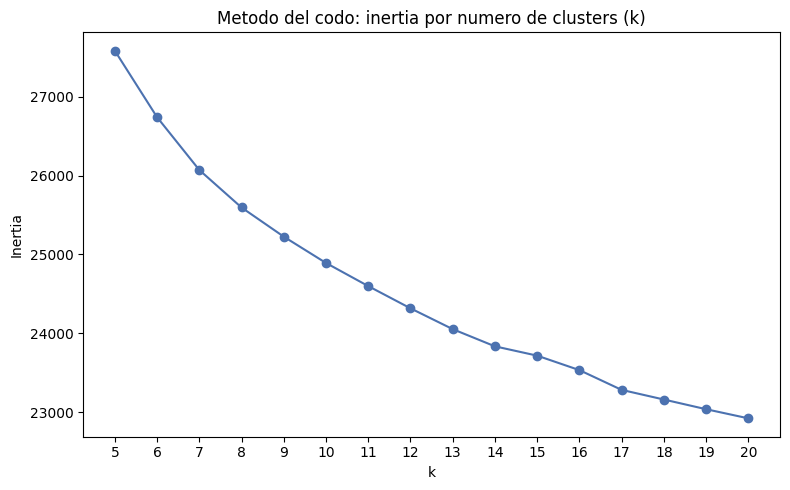

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabla_k["k"], tabla_k["inertia"], marker="o", color="#4c72b0")
ax.set_title("Metodo del codo: inertia por numero de clusters (k)")
ax.set_xlabel("k")
ax.set_ylabel("Inertia")
ax.set_xticks(tabla_k["k"])
fig.tight_layout()
fig.savefig(RUTA_FIGURES / "codo_inertia.png", dpi=150)
plt.show()


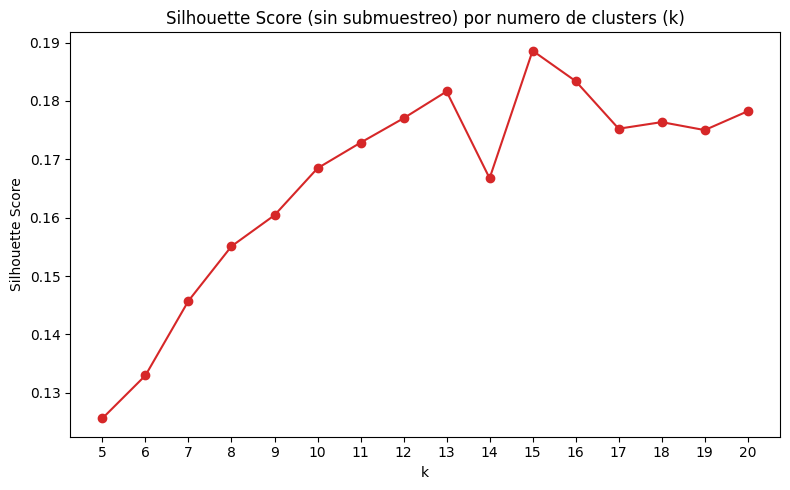

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabla_k["k"], tabla_k["silhouette"], marker="o", color="#d62728")
ax.set_title("Silhouette Score (sin submuestreo) por numero de clusters (k)")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(tabla_k["k"])
fig.tight_layout()
fig.savefig(RUTA_FIGURES / "silhouette_por_k.png", dpi=150)
plt.show()


In [8]:
K_OPTIMO = int(tabla_k.loc[tabla_k["silhouette"].idxmax(), "k"])
print(f"k optimo (mayor Silhouette Score en el rango {K_MIN}-{K_MAX}): {K_OPTIMO}")


k optimo (mayor Silhouette Score en el rango 5-20): 15


## 4. Entrenamiento del modelo KMeans final

Se entrena KMeans con el `k` optimo encontrado en la seccion anterior.

In [9]:
kmeans = KMeans(n_clusters=K_OPTIMO, random_state=SEMILLA, n_init=10)
clusters = kmeans.fit_predict(embeddings)

tamanos = pd.Series(clusters).value_counts().sort_index()
print(f"Distribucion de correos por cluster (k={K_OPTIMO}):")
print(tamanos)


Distribucion de correos por cluster (k=15):
0     2726
1     4496
2     1567
3     2883
4     5459
5     2776
6     1407
7     2886
8     1838
9     2632
10     916
11    3791
12    1523
13    2171
14     995
Name: count, dtype: int64


## 5. Perfil de cada arquetipo

Para cada cluster se extraen:

- Las **10 palabras/frases mas frecuentes** (TF-IDF promedio dentro del cluster,
  con 1 y 2 palabras, excluyendo stopwords en ingles).
- Los **3 correos mas cercanos al centroide** del cluster (mayor similitud coseno),
  como muestra representativa.
- El **tamano** del cluster (cantidad de correos).

El centroide se calcula como el promedio de los embeddings normalizados del
cluster, vuelto a normalizar (misma convencion que usara el servidor MCP).

In [10]:
vectorizador_tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    min_df=5,
    ngram_range=(1, 2),
)
textos_phishing = phishing["text_clean"].astype(str).to_numpy()
matriz_tfidf = vectorizador_tfidf.fit_transform(textos_phishing)
vocabulario = np.array(vectorizador_tfidf.get_feature_names_out())

perfiles_cluster = {}

for id_cluster in range(K_OPTIMO):
    mascara = clusters == id_cluster
    tamano = int(mascara.sum())

    # Terminos TF-IDF mas distintivos del cluster.
    promedio_tfidf = np.asarray(matriz_tfidf[mascara].mean(axis=0)).ravel()
    indices_top = promedio_tfidf.argsort()[::-1][:N_TERMINOS_POR_CLUSTER]
    top_phrases = list(vocabulario[indices_top])

    # Centroide: promedio de embeddings normalizados, vuelto a normalizar.
    centroide = embeddings[mascara].mean(axis=0)
    centroide = centroide / np.linalg.norm(centroide)

    # Correos mas cercanos al centroide (mayor similitud coseno).
    similitudes = embeddings[mascara] @ centroide
    top_local = similitudes.argsort()[::-1][:N_EJEMPLOS_POR_CLUSTER]
    indices_globales = np.where(mascara)[0][top_local]
    ejemplos = [textos_phishing[i][:LARGO_EJEMPLO_TEXTO] for i in indices_globales]

    perfiles_cluster[id_cluster] = {
        "top_phrases": top_phrases,
        "representative_examples": ejemplos,
        "sample_count": tamano,
    }

for id_cluster, perfil in perfiles_cluster.items():
    print(f"\nCluster {id_cluster} (n={perfil['sample_count']}):")
    print("  top_phrases:", perfil["top_phrases"])



Cluster 0 (n=2726):
  top_phrases: ['url', 'com', 'ecard', 'http', 'link', 'card', 'para', 'www', 'click', 'message']

Cluster 1 (n=4496):
  top_phrases: ['url', 'love', 'men', 'video', 'new', 'women', 'girls', 'life', 'make', 'watch']

Cluster 2 (n=1567):
  top_phrases: ['company', 'statements', 'business', 'logo', 'securities', 'report', 'stock', 'market', 'investment', 'information']

Cluster 3 (n=2883):
  top_phrases: ['email', '000', 'free', 'payment', 'website', 'information', 'money', 'program', 'mail', 'com']

Cluster 4 (n=5459):
  top_phrases: ['online', 'health', 'viagra', 'medications', 'pills', 'url', 'pharmacy', 'prices', 'meds', 'http']

Cluster 5 (n=2776):
  top_phrases: ['replica', 'watches', 'replica watches', 'rolex', 'replica classics', 'classics', 'watch', 'url', 'watches replica', 'replica watch']

Cluster 6 (n=1407):
  top_phrases: ['cnn', 'alert', 'custom', 'custom alert', 'alerts', 'cnn alerts', 'alerts custom', 'cable news', 'news network', 'cnn com']

Cluster

## 6. Etiquetas semanticas de cada arquetipo

Las metricas de la seccion anterior (top_phrases, ejemplos representativos) se
inspeccionaron manualmente para asignarle a cada cluster:

- Una **etiqueta descriptiva** del patron de ataque dominante.
- La **emocion principal explotada** (urgencia, miedo, confianza, codicia,
  curiosidad).
- La **tactica de ingenieria social predominante** (autoridad, escasez,
  reciprocidad, prueba social, simpatia).

Esta asignacion es un juicio del analista basado en el contenido observado (no un
calculo automatico): no existe una formula que derive "codicia" o "autoridad" de
un vector de TF-IDF. Si se vuelve a correr este notebook con un corpus distinto
(u otro `k` optimo), estas etiquetas deben revisarse contra los nuevos
`top_phrases`/`representative_examples` antes de confiar en ellas.

In [11]:
ETIQUETAS_ARQUETIPOS = {
    0: {
        "label": "Spam farmaceutico y de pastillas para adelgazar con frases de marketing concatenadas (evasion de filtros)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    1: {
        "label": "Spam de atraccion y mejora sexual masculina con tono agresivo y pseudo-respaldo de 'estudios'",
        "dominant_emotion": "curiosidad",
        "social_engineering_tactic": "autoridad",
    },
    2: {
        "label": "Spam de acciones bursatiles 'pump and dump' (boletines de inversion falsos)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "autoridad",
    },
    3: {
        "label": "Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    4: {
        "label": "Farmacia en linea no autorizada (medicamentos sin receta)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    5: {
        "label": "Venta de relojes de imitacion de marcas de lujo (replica Rolex)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "autoridad",
    },
    6: {
        "label": "Suplantacion de boletin de noticias (alertas CNN falsas)",
        "dominant_emotion": "confianza",
        "social_engineering_tactic": "autoridad",
    },
    7: {
        "label": "Spam de aumento de tamano masculino con garantia de resultados",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "prueba social",
    },
    8: {
        "label": "Spam ofuscado de agrandamiento masculino con pseudo-respaldo medico (evasion de filtros)",
        "dominant_emotion": "confianza",
        "social_engineering_tactic": "autoridad",
    },
    9: {
        "label": "Spam ofuscado de medicamentos genericos (evasion de filtros)",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    10: {
        "label": "Spam de hipotecas y prestamos preaprobados",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    11: {
        "label": "Fraude de anticipo / transferencia de fondos (estafa 419)",
        "dominant_emotion": "urgencia",
        "social_engineering_tactic": "autoridad",
    },
    12: {
        "label": "Venta de software pirata a precio muy bajo",
        "dominant_emotion": "codicia",
        "social_engineering_tactic": "escasez",
    },
    13: {
        "label": "Phishing de verificacion y suspension de cuenta",
        "dominant_emotion": "miedo",
        "social_engineering_tactic": "escasez",
    },
    14: {
        "label": "Spam de bienestar generico con tono amistoso (plantilla anti-filtros de destinatario aleatorio)",
        "dominant_emotion": "confianza",
        "social_engineering_tactic": "simpatia",
    },
}

faltantes = set(perfiles_cluster) - set(ETIQUETAS_ARQUETIPOS)
assert not faltantes, f"Faltan etiquetas manuales para los clusters: {faltantes}"


## 7. Guardado de los artifacts

Se combina el perfil estadistico de cada cluster con su etiqueta semantica y se guardan dos archivos en `artifacts/`, que el servidor MCP carga al iniciar:

- `archetypes.json`: perfil completo de cada arquetipo.
- `kmeans_archetypes.pkl`: el modelo KMeans entrenado (se usa para clasificar un correo nuevo contra los arquetipos por cercania de centroide).

In [12]:
archetypes_json = {}
for id_cluster, perfil in perfiles_cluster.items():
    etiqueta = ETIQUETAS_ARQUETIPOS[id_cluster]
    archetypes_json[str(id_cluster)] = {
        "label": etiqueta["label"],
        "top_phrases": perfil["top_phrases"],
        "dominant_emotion": etiqueta["dominant_emotion"],
        "social_engineering_tactic": etiqueta["social_engineering_tactic"],
        "sample_count": perfil["sample_count"],
        "representative_examples": perfil["representative_examples"],
    }

archivo_final = {
    "meta": {
        "modelo_embedding": MODELO_EMBEDDING,
        "semilla": SEMILLA,
        "fuente_datos": FUENTE_DATOS,
        "n_correos_phishing": len(phishing),
        "k_optimo": K_OPTIMO,
        "k_min": K_MIN,
        "k_max": K_MAX,
        "fecha_generacion": datetime.now(timezone.utc).isoformat(),
    },
    "archetypes": archetypes_json,
}

with open(ARCHIVO_ARQUETIPOS, "w", encoding="utf-8") as f:
    json.dump(archivo_final, f, ensure_ascii=False, indent=2)
print(f"Arquetipos guardados en: {ARCHIVO_ARQUETIPOS}")

with open(ARCHIVO_KMEANS, "wb") as f:
    pickle.dump(kmeans, f)
print(f"Modelo KMeans guardado en: {ARCHIVO_KMEANS}")


Arquetipos guardados en: C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\pattern-archetype-MCP\artifacts\archetypes.json
Modelo KMeans guardado en: C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\pattern-archetype-MCP\artifacts\kmeans_archetypes.pkl


## 8. Resumen final

In [13]:
print("=" * 78)
print("RESUMEN DE LA CONSTRUCCION DE ARQUETIPOS DE PHISHING")
print("=" * 78)
print(f"Correos de phishing analizados: {len(phishing)}")
print(f"k optimo: {K_OPTIMO}\n")

resumen = pd.DataFrame([
    {
        "cluster_id": cid,
        "label": archetypes_json[str(cid)]["label"],
        "sample_count": archetypes_json[str(cid)]["sample_count"],
        "pct": archetypes_json[str(cid)]["sample_count"] / len(phishing),
        "dominant_emotion": archetypes_json[str(cid)]["dominant_emotion"],
        "social_engineering_tactic": archetypes_json[str(cid)]["social_engineering_tactic"],
    }
    for cid in range(K_OPTIMO)
]).sort_values("sample_count", ascending=False)

for _, fila in resumen.iterrows():
    print(f"[{fila['cluster_id']}] {fila['label']}")
    print(f"      n={fila['sample_count']} ({fila['pct']:.1%})  "
          f"emocion={fila['dominant_emotion']}  tactica={fila['social_engineering_tactic']}")

print("=" * 78)


RESUMEN DE LA CONSTRUCCION DE ARQUETIPOS DE PHISHING
Correos de phishing analizados: 38066
k optimo: 15

[4] Farmacia en linea no autorizada (medicamentos sin receta)
      n=5459 (14.3%)  emocion=codicia  tactica=escasez
[1] Spam de atraccion y mejora sexual masculina con tono agresivo y pseudo-respaldo de 'estudios'
      n=4496 (11.8%)  emocion=curiosidad  tactica=autoridad
[11] Fraude de anticipo / transferencia de fondos (estafa 419)
      n=3791 (10.0%)  emocion=urgencia  tactica=autoridad
[7] Spam de aumento de tamano masculino con garantia de resultados
      n=2886 (7.6%)  emocion=codicia  tactica=prueba social
[3] Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM)
      n=2883 (7.6%)  emocion=codicia  tactica=escasez
[5] Venta de relojes de imitacion de marcas de lujo (replica Rolex)
      n=2776 (7.3%)  emocion=codicia  tactica=autoridad
[0] Spam farmaceutico y de pastillas para adelgazar con frases de marketing concatenadas (evasion de filtros)
      n=27